In [1]:
import numpy as np
from numpy.polynomial import chebyshev as cheb
from scipy import optimize
import matplotlib.pyplot as plt
from tqdm import tqdm
import matplotlib as mpl
import matplotlib.cm as cm
from scipy.ndimage import zoom, gaussian_filter
import uuid

# Force Modell

In [2]:
Lp = 1.5 # um Persistence length
kbT = 1

In [3]:
def x_entropic_force(Fe):
    return 1 / np.tanh(2 * Lp * Fe / kbT) - kbT / (2 * Lp * Fe)

def dx_entropic_force(Fe):
    return 1 / (2 * Lp * Fe**2 / kbT) - 2 * Lp / kbT / np.sinh(2 * Lp * Fe / kbT)**2

In [4]:
def create_F(k, sample_density_x=1e-3, n_iter_equalize=5, x_max_full=5, cheb_subsampling = 16):
    
    ''' Creates a force curve for a given w.
        We return a chebychev polynomial that
        approximates the entire curve.

        From the experimental force rate w:
        k = w / v
    '''

    # Find F*, the transition from entropic to hookean force.
    res = optimize.root_scalar(lambda fe: dx_entropic_force(fe) - 1/k, bracket=(1e-12, 30))
    F_star = res.root

    # Determine the x range for forces to occur between 0 and F*
    x_min = x_entropic_force(sample_density_x)
    x_max = x_entropic_force(F_star)

    # Construct an even x grid of forces using the derivative of x
    n_x = max(int((x_max - x_min) / sample_density_x), 2)
    F  = np.linspace(1e-12, F_star, n_x)
    for _ in range(n_iter_equalize):
        cdx = np.cumsum(1/dx_entropic_force(F))
        cdx = cdx - cdx[0]
        cdx = cdx / cdx[-1]
        F = cdx * (F_star) + sample_density_x
    x = x_entropic_force(F)

    # The Hookean tail
    hook_tail_length = x_max_full - x_max
    xh = np.linspace(sample_density_x, hook_tail_length, int((hook_tail_length - sample_density_x) / sample_density_x))
    Fh = k * xh + F[-1]

    x = np.concatenate(([0], x, xh + x[-1]))
    F = np.concatenate(([0], F, Fh))

    C = cheb.Chebyshev.fit(x, F, len(x)//cheb_subsampling)
    
    return C, x, F

# Simulate Trajectories

In [5]:
def sim(C, ru0, xu, v=0.2, dt=1e-2):
    t = 0
    ft = [C(t*v)]
    while True:
        assert v*t < C.domain.max(), "Force left Chebychev domain"
        pu = np.clip(dt * ru0 * np.exp(C(v*t)*xu), 0, 1)
        if pu > np.random.rand(1):
            break
        ft.append(C(v*t))
        t += dt

    return np.array(ft)

Text(0, 0.5, 'F')

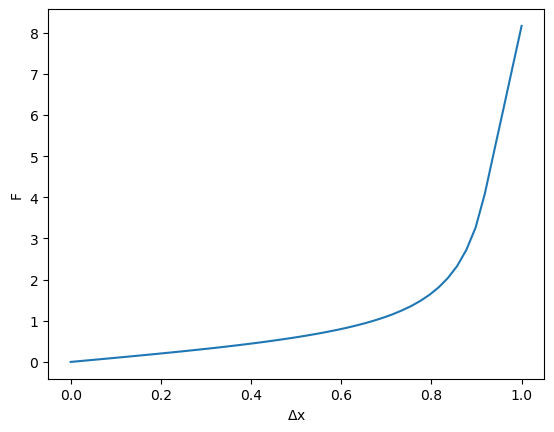

In [6]:
C, _, _ = create_F(50)
x = np.linspace(0, 1)
F = C(x)
plt.plot(x,F)
plt.xlabel("$\Delta$x")
plt.ylabel("F")

# Simulate Trajectories

In [7]:
def generate_trajectories(ru0, xu, v_dist, N_trajectories, cheb_force, dt=1e-2, use_tqdm=True):

    Ts = []
    v_it = tqdm(range(N_trajectories)) if use_tqdm else range(N_trajectories)
    for v in v_it:
        v = v_dist()
        F = sim(cheb_force, ru0_GT, xu_GT, v=v, dt=dt)
        Ts.append((v, F))

    return Ts

# Inference

In [8]:
def likelihood(Fs, xu, ru0, dt):

    global pbar

    ''' Unnormalized logarithmic likelihood of the force curve
        under parameter xu and ru0. This does not include the
        time step, which scales the likelihood exponentially. '''

    logp = 0
    

    for F in Fs:
        N = len(F)
    
        F_stay_bound  = F[:-1]
        F_unbind      = F[-1]

        with np.errstate(divide='ignore'):
            logp_stay_bound  = np.log(1 - np.clip(dt * ru0 * np.exp(F_stay_bound * xu), 0, 1))
            logp_unbind = np.log(dt * ru0 * np.exp(F_unbind * xu))
            logp += np.sum(logp_unbind) + np.sum(logp_stay_bound)

    pbar.update(1)
    return logp

def inference_grid(Ts, ru0_space, xu_space, dt):
    global pbar
    LOGP = 0
    RU0, XU = np.meshgrid(ru0_space, xu_space)
    Fs = [F for v, F in Ts]
    vecfun = np.vectorize(lambda xu, ru0: likelihood(Fs, xu, ru0, dt))
    RU0, XU = np.meshgrid(ru0, xu)
    with tqdm(total=resolution**2) as pbar:
        LOGP = vecfun(XU, RU0)

    LOGP -= LOGP.max()
    return LOGP

# Plotting

In [9]:
def log_perc(LOGP, perc):
    ''' Bipartite the density function at a certain
        mass percentile and return the threshold
        logprobability. '''
    P = np.exp(LOGP)
    P_flat = np.sort(P.flatten())
    CDF = np.cumsum(P_flat)
    CDF = CDF / CDF[-1]
    idx = np.argmax(CDF > (100 - perc)/100)
    return np.log(P_flat[idx])
    

def color_blob_plot(LOGP, perc, extent, color='k', alpha=0.5, upscaler=2, filter=0):
    LOGP90 = log_perc(LOGP, perc)
    plt.contourf(LOGP, origin='lower', extent=extent, levels=[LOGP90, 0], alpha=alpha, linestyles='-', colors=[color])

def color_contour_plot(LOGP, perc, extent, color='k', alpha=0.5, upscaler=2, filter=0):
    LOGP90 = log_perc(LOGP, perc)
    plt.contour(LOGP, origin='lower', extent=extent, levels=[LOGP90], alpha=alpha, linestyles='-', colors=[color])

# The actual thingy

## Generate Trajectories

In [10]:
vmin = 0.025
vmax = 0.4
ru0_GT = 0.05
xu_GT  = 0.2
dt = 1e-1
N_traj = 2500

norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
v_col = cm.ScalarMappable(norm=norm, cmap=cm.rainbow).to_rgba

v_dist = lambda: np.random.uniform(vmin, vmax)
T_mix = generate_trajectories(ru0_GT, xu_GT, v_dist, N_traj, C, dt=dt)

T_v = []
for v in np.linspace(vmin, vmax, 5):
    v_dist = lambda: v
    T = generate_trajectories(ru0_GT, xu_GT, v_dist, N_traj, C, dt=dt)
    T_v.append((v, T))



100%|██████████████████████████████████████████████████████████████████████████| 2500/2500 [00:07<00:00, 356.04it/s]


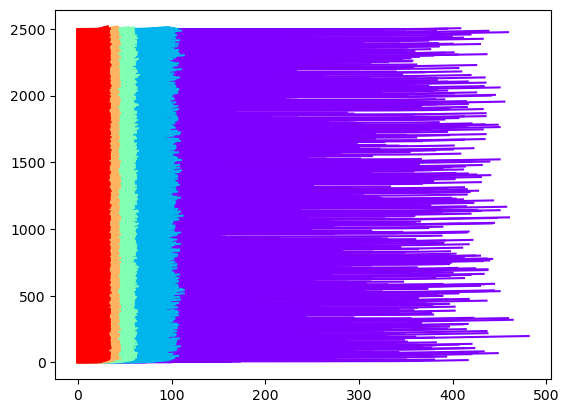

In [11]:
for v_, T_ in T_v:
    for i, (v_, f) in enumerate(T_):
        plt.plot(f+i, color=v_col(v_))

## Calculate the posteriors

In [12]:
resolution = 200
xu_max = xu_GT * 2
ru0_max = ru0_GT * 2
xu = np.linspace(0, xu_max, resolution)
ru0 = np.linspace(0, ru0_max, resolution)
extent = (0, ru0_max, 0, xu_max)

LOGPmix  = inference_grid(T_mix, ru0, xu, dt)
LOGPv = []

for v_, T_ in T_v:
    LOGP_ = inference_grid(T_, ru0, xu, dt)
    LOGPv.append((v_, LOGP_))

40001it [28:08, 23.69it/s]                                                                                          
 20%|██████████████▊                                                           | 7974/40000 [05:57<23:54, 22.32it/s]


KeyboardInterrupt: 

In [ ]:
perc = 99

scale = 1
filter = 1

for v_, LOGP_ in LOGPv:
    #LOGP_ /= 1 DONT DO THAT, IT CHANGES THE DATA FFS
    P = np.exp(LOGP_)
    P = np.clip(gaussian_filter(zoom(P, scale), filter), 0, np.inf)
    LOGP_ = np.log(P)
    color_blob_plot(LOGP_, perc, extent, color=v_col(v_), alpha=0.4)

P = np.exp(LOGPmix)
P = np.clip(gaussian_filter(zoom(P, scale), filter), 0, np.inf)
LOGP_ = np.log(P)
color_contour_plot(LOGP_, perc, extent, color='k', alpha=1)

plt.axvline(ru0_GT)
plt.axhline(xu_GT)
plt.savefig(f"img/{uuid.uuid4()}.png", dpi=300)

In [ ]:
A = np.eye(3)
L = [A]
print(L)
for a in L:
    a /= 3

print(L)